<a href="https://colab.research.google.com/github/copr4214/Relojero-ciego-python/blob/main/Seleccion_cumulativa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import random
import matplotlib.pyplot as plt

# Conjunto de caracteres disponibles (letras mayúsculas y espacio)
VALID_CHARS = " ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def random_string(length):
    """Genera una cadena aleatoria de la longitud dada."""
    return "".join(random.choice(VALID_CHARS) for _ in range(length))

def mutation(parent, mutation_rate=0.05):
    """Aplica mutaciones aleatorias a una cadena (padre) para crear un hijo."""
    child = []
    for char in parent:
        if random.random() < mutation_rate:
            child.append(random.choice(VALID_CHARS))
        else:
            child.append(char)
    return "".join(child)

def fitness(text, target):
    """Calcula cuántos caracteres coinciden exactamente en su posición con la frase objetivo."""
    return sum(1 for c1, c2 in zip(text, target) if c1 == c2)

# ==========================================
# 1. SELECCIÓN SIMPLE (AZAR PURO)
# ==========================================
def single_step_selection(target, max_iterations=100000):
    print("\n[Ejecutando] Selección Simple (Azar Puro)...")
    length = len(target)
    iterations = 0
    history = []

    while iterations < max_iterations:
        iterations += 1
        current = random_string(length)
        fit = fitness(current, target)
        history.append(fit)

        #######################################################################
        ###############   IMPRIMIR LAS GENERACIONES DE 1000 EN 1000 ###########
        ###############   IMPRIMIR LAS GENERACIONES DE 1000 EN 1000 ###########
        ######################################################################

        if iterations == 1 or iterations % 1000 == 0 or current == target:
            print(f"Gen {iterations:6d}: {current} (Aciertos: {fit:2d}/{length})")

        if current == target:
            print(f"¡Encontrado en selección simple! Generación: {iterations}")
            return iterations, history

    print(f"-> Detenido por el límite de seguridad (STOP) a las {max_iterations} iteraciones.")
    print("   (La selección simple por azar puro jamás logrará la frase completa en un tiempo razonable).")
    return max_iterations, history

# ==========================================
# 2. SELECCIÓN ACUMULATIVA (DAWKINS)
# ==========================================
def cumulative_selection(target,
                         num_offspring=100, # Ojo que en esta línea, como la SN es ciega, se selecciona de estos 100 descencientes el que tenga mejor fitness
                         mutation_rate=0.05): # Esta es la tasa de mutación ALEATORIA para cualquier letra
                                              # obviamente es una tasa de mutacion extremadamente ALTA incluso para una procariota, pero es con fines ilustrativos
    print("\n[Ejecutando] Selección Acumulativa (Evolutiva)...")
    length = len(target)
    current = random_string(length)
    iterations = 0
    history = [fitness(current, target)]

    while current != target:
        iterations += 1
        # Generar descendientes mutados a partir del padre actual
        offspring = [mutation(current, mutation_rate) for _ in range(num_offspring)]

        # Seleccionar el mejor descendiente/ mejor fitness (el que tenga más aciertos)
        best_child = max(offspring, key=lambda x: fitness(x, target))

        current = best_child
        fit = fitness(current, target)
        history.append(fit)

       # Same
        if iterations == 1 or iterations % 10 == 0 or fit == length:
            print(f"Gen {iterations:6d}: {current} (Aciertos: {fit:2d}/{length})")

        if current == target:
            print(f"¡Frase encontrada por selección acumulativa en la generación {iterations}!")
            break

    return iterations, history

Frase objetivo: 'EL INGENIOSO HIDALGO'
Longitud de la frase: 20 caracteres.

[Ejecutando] Selección Acumulativa (Evolutiva)...
Gen      1: ULOVHXSUAQMQMPHVMFHO (Aciertos:  2/20)
Gen     10: EL JHGEUDOCE HIVMJGO (Aciertos: 11/20)
Gen     20: EL INGEYIOSO HINMLGO (Aciertos: 17/20)
Gen     30: EL INGEYIOSO HIDALGO (Aciertos: 19/20)
Gen     40: EL INGENIOSO HIDALGO (Aciertos: 20/20)
¡Frase encontrada por selección acumulativa en la generación 40!

[Ejecutando] Selección Simple (Azar Puro)...
Gen      1: HPLTLMMWKWZCLGYFMRIJ (Aciertos:  0/20)
Gen   1000: JNTQELU TASL YUTHCUW (Aciertos:  2/20)
Gen   2000: VUXWPMGNADLOFEJNKHPT (Aciertos:  2/20)
Gen   3000: TZCYZCRLZMZCI FXXPCU (Aciertos:  0/20)
Gen   4000: AQGKNZCHGVJKSXRPMVDF (Aciertos:  1/20)
Gen   5000: OVVMLZKQZLQCRDGNKXGR (Aciertos:  1/20)
Gen   6000: IA KZUWXWALR RUKQVHY (Aciertos:  2/20)
Gen   7000: FBGZKIDOJ X OCALNESX (Aciertos:  0/20)
Gen   8000: KDZRZKNOVSIOEACJEGQT (Aciertos:  1/20)
Gen   9000: IBKZDPJZQTGFT VLCXJS (Aciertos:  0/2

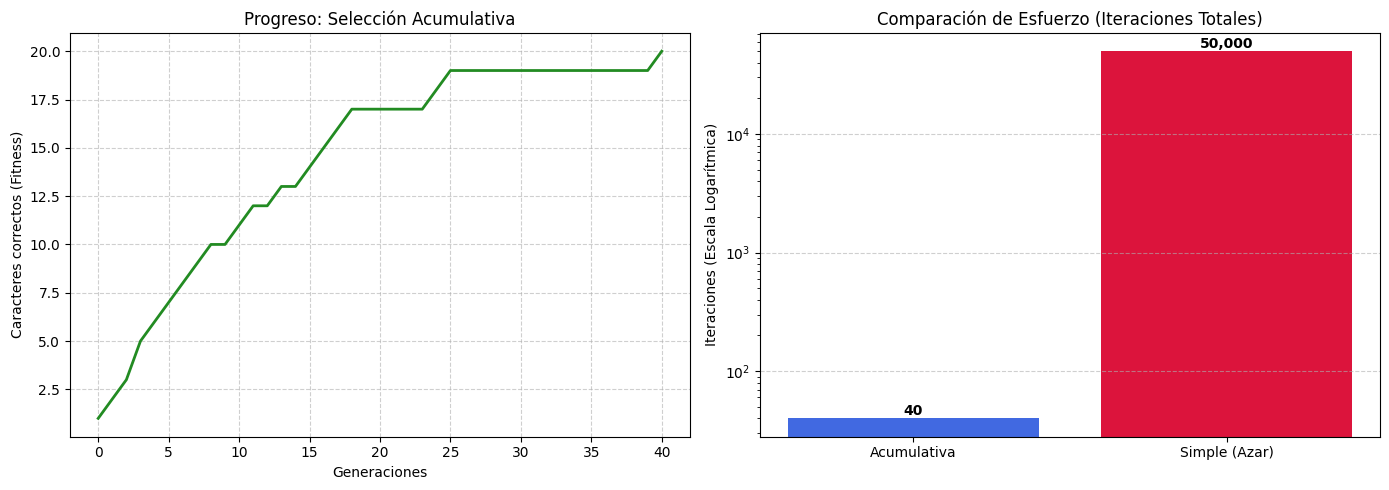

In [11]:
# ==========================================
# ==========================================
if __name__ == "__main__":
    # Puedes cambiar esta frase por la que prefieras (recuerda usar mayúsculas y espacios)
    target_phrase = "EL INGENIOSO HIDALGO"

    print(f"Frase objetivo: '{target_phrase}'")
    print(f"Longitud de la frase: {len(target_phrase)} caracteres.")

    # 1. Ejecutar Selección Acumulativa
    iters_cumul, hist_cumul = cumulative_selection(target_phrase)

    # 2. Ejecutar Selección Simple con un STOP de seguridad
    max_safe_limit = 50000
    iters_simp, hist_simp = single_step_selection(target_phrase, max_iterations=max_safe_limit)

    # ==========================================
    # GENERACIÓN DE GRÁFICAS COMPARATIVAS
    # ==========================================
    print("\nGenerando gráficas comparativas...")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfica 1: Progreso de la Selección Acumulativa hacia la meta
    ax1.plot(hist_cumul, color='forestgreen', lw=2)
    ax1.set_title("Progreso: Selección Acumulativa")
    ax1.set_xlabel("Generaciones")
    ax1.set_ylabel("Caracteres correctos (Fitness)")
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Gráfica 2: Comparación de Iteraciones Totales (Escala Logarítmica)
    methods = ['Acumulativa', 'Simple (Azar)']
    values = [iters_cumul, iters_simp]
    bars = ax2.bar(methods, values, color=['royalblue', 'crimson'])
    ax2.set_title("Comparación de Esfuerzo (Iteraciones Totales)")
    ax2.set_ylabel("Iteraciones (Escala Logarítmica)")
    ax2.set_yscale('log') # Importante porque la diferencia es abismal
    ax2.grid(axis='y', linestyle='--', alpha=0.6)

    # Añadir etiquetas con los valores exactos sobre las barras
    for bar in bars:
        yval = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:,}', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()